
# Data Preparation of the Heart Diagnoses file

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib as plt
import sys
import os
sys.path.append(os.path.abspath(os.path.join(os.getcwd(), '../..')))
from src.utils import data_understanding as du

heart_diagnoses_df = pd.read_csv("../../data/raw/heart_diagnoses_1.csv")
heart_diagnoses_df['subject_id'].nunique()

4392

In [2]:
heart_diagnoses_df

,note_id,subject_id,hadm_id,note_type,note_seq,charttime,storetime,HPI,physical_exam,chief_complaint,...,ECG,MRI,reports,subject_id_dx,icd_code,long_title,gender,age,anchor_year,dod
0,10000980-DS-20,10000980,29654838,DS,20,2188-01-06 03:00:00,2188-01-07 23:49:00,":\n___ yo woman with h/o hypertension, hyperli...","Admission exam:\nGENERAL- Oriented x3. Mood, a...",\nShortness of breath\n \n,...,['___ 7:56:06 ___ \nBaseline artifact. Sinus...,[],Sinus bradycardia with sinus arrhythmia | Prol...,10000980,I50,Heart failure,F,75.0,2186.0,2193-08-26
1,10000980-DS-21,10000980,26913865,DS,21,2189-07-04 03:00:00,2189-07-04 22:50:00,":\nThis is a ___ M with history of diabetes, d...",ADMISSION EXAM:\nGeneral- appears comfortable...,\ndyspnea\n \n,...,[],[],Sinus bradycardia with sinus arrhythmia | Prol...,10000980,I21,Acute myocardial infarction,F,75.0,2186.0,2193-08-26
2,10002013-DS-8,10002013,24760295,DS,8,2160-07-13 03:00:00,2160-07-15 16:59:00,":\n___ w/ PMH of CAD s/p PCI x3, s/p off-pump ...",Admission:\nVS- T 99.4 BP 157/88 HR 118 RR 24 ...,\nchest pain\n \n,...,['on admission- Sinus tachycardia. Extensive S...,[],Sinus tachycardia | Extensive ST-T changes may...,10002013,I21,Acute myocardial infarction,NaN,NaN,NaN,NaN
3,10002155-DS-8,10002155,23822395,DS,8,2129-08-19 03:00:00,2129-08-20 15:29:00,:\n___ is a ___ yo female with a past medical ...,"GENERAL: WDWN in NAD. Oriented x3. Mood, affec...",\nchest pressure\n \n,...,[': new LBBB with STE in V1 -V3 & V5 that in ...,[],*** CONSIDER ACUTE ST ELEVATION MI *** | Sinus...,10002155,I21,Acute myocardial infarction,NaN,NaN,NaN,NaN
4,10004457-DS-10,10004457,28723315,DS,10,2141-08-14 03:00:00,2141-08-14 21:50:00,:\nMr. ___ is a ___ with a hx of CAD (s/p DES ...,On Admission:\nVS- 97.8 157/64 101 18 98% RA \...,"\nAbnormal Stress Test, New AI\n \n",...,['(see exercise report for details). Resting s...,[],Sinus rhythm | Normal ECG,10004457,I35,Nonrheumatic aortic valve disorders,M,66.0,2140.0,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4859,13690559-DS-19,19998596,24860241,DS,19,2180-01-24 03:00:00,2180-01-24 20:12:00,:\nMs ___ is a ___ year old woman with carotid...,ADMISSION EXAM\n=====================\nVITALS:...,\nRight shoulder pain\n \n,...,['___:\nAtrial flutter with 4:1 conduction and...,[],Possible atrial flutter with rapid ventricular...,13690559,I48,Atrial fibrillation and flutter,NaN,NaN,NaN,NaN
4860,14997789-DS-12,19998597,23720781,DS,12,2131-10-11 03:00:00,2131-10-11 16:17:00,:\nMs. ___ is a ___ woman with renal cell carc...,Physical Exam:\nVS: T: T 95.7 bp 102/60 HR 1...,\nDyspnea\n \n,...,[],[],Sinus tachycardia. | Possible anterior infarct...,14997789,I31,Other diseases of pericardium,NaN,NaN,NaN,NaN
4861,10754991-DS-13,19998598,26940500,DS,13,2135-04-03 03:00:00,2135-04-05 00:12:00,":\n___ T2DM, fibromyalgia, GERD, hypothyroidis...",=================\nADMISSION EXAM:\n==========...,\nPalpitations\n \n,...,['(___): Narrow complex tachycardia. Supravent...,[],Supraventricular tachycardia | Sinus rhythm | ...,10754991,I47,Paroxysmal tachycardia,NaN,NaN,NaN,NaN
4862,17922874-DS-8,19998599,20343031,DS,8,2158-05-23 03:00:00,2158-05-23 20:55:00,":\n___ with H/O of type 2 diabetes mellitus, h...","General: Middle aged Caucasian man in NAD, com...","\nAbdominal pain, nausea, vomiting, and diarrh...",...,['Study Date of ___ 7:51:52 ___\nSinus rhythm ...,[],*** CONSIDER ACUTE ST ELEVATION MI *** | Sinus...,17922874,I30,Acute pericarditis,NaN,NaN,NaN,NaN


In [3]:
# Extract gender from HPI free-text using regex rules and assign to 'gender'.

import re

def detect_gender_regex(text):
    if pd.isna(text):
        return 'unknown'
    
    text_lower = text.lower()

    text_lower = text.lower()

    if match := re.search(r"\b(?:sex|gender|patient sex)\b[^a-z]*\b(m|male)\b", text_lower):
        return "M"
    if match := re.search(r"\b(?:sex|gender|patient sex)\b[^a-z]*\b(f|female)\b", text_lower):
        return "F"

    if re.search(r"\b(mr\.?|mister)\b", text_lower):
        return "M"
    if re.search(r"\b(mrs?\.?|miss|ms\.?)\b", text_lower):
        return "F"
    if re.search(r"\b(he|his|him|himself)\b", text_lower):
        return "M"
    if re.search(r"\b(she|her|hers|herself)\b", text_lower):
        return "F"
    if re.search(r"\b(man|men|male|boy|gentleman)\b", text_lower):
        return "M"
    if re.search(r"\b(woman|women|female|girl|lady)\b", text_lower):
        return "F"

    return np.nan

heart_diagnoses_df['gender'] = heart_diagnoses_df['HPI'].apply(detect_gender_regex)

grouped = heart_diagnoses_df[['subject_id', 'hadm_id', 'gender']].groupby(['subject_id', 'hadm_id'])
# Print subject, admission, and gender
for (subject_id, hadm_id), group in grouped:
    print(f"Subject ID: {subject_id}, HADM ID: {hadm_id}, Genders: {group['gender'].tolist()}") 



Subject ID: 10000980, HADM ID: 26913865, Genders: ['F']
Subject ID: 10000980, HADM ID: 29654838, Genders: ['F']
Subject ID: 10002013, HADM ID: 24760295, Genders: ['F']
Subject ID: 10002155, HADM ID: 23822395, Genders: ['F']
Subject ID: 10004457, HADM ID: 28723315, Genders: ['M']
Subject ID: 10007058, HADM ID: 22954658, Genders: ['M']
Subject ID: 10010424, HADM ID: 28388172, Genders: ['M']
Subject ID: 10012343, HADM ID: 27658045, Genders: ['F']
Subject ID: 10013569, HADM ID: 22891949, Genders: ['F']
Subject ID: 10014651, HADM ID: 20051301, Genders: ['M']
Subject ID: 10017531, HADM ID: 20668418, Genders: ['M']
Subject ID: 10017886, HADM ID: 20015927, Genders: ['F']
Subject ID: 10018684, HADM ID: 26649049, Genders: ['M']
Subject ID: 10023117, HADM ID: 28872262, Genders: ['M']
Subject ID: 10024331, HADM ID: 27524226, Genders: ['M']
Subject ID: 10024913, HADM ID: 27207228, Genders: ['M']
Subject ID: 10024982, HADM ID: 25153817, Genders: ['M']
Subject ID: 10025647, HADM ID: 28899194, Genders

In [4]:
# Drop columns not relevant for the analysis: free-text, reports, and other non-essential fields

heart_diagnoses_df = heart_diagnoses_df.drop(columns=["CT", "MRI", "X-ray", "Ultrasound", "ECG", "CATH", "invasions", "reports","chief_complaint", "physical_exam","HPI","anchor_year","note_seq","note_type","charttime","storetime"])
heart_diagnoses_df_columns= du.get_cols(heart_diagnoses_df)
print("Columns in heart diagnoses dataset:",heart_diagnoses_df_columns) 


Columns in heart diagnoses dataset: ['note_id', 'subject_id', 'hadm_id', 'subject_id_dx', 'icd_code', 'long_title', 'gender', 'age', 'dod']


In [5]:
# Handling missing value: 
# age and gender have missing values but they can be useful for the analysis, so we will keep them
# dod has many missing values; it may mean the patient is alive or data is missing, so it's ambiguous. We will drop it

heart_diagnoses_df=heart_diagnoses_df.drop(columns=["dod"])
heart_diagnoses_df['subject_id'].nunique()


4392

In [6]:
# Identify and remove rare ICD codes using IQR-based outlier rule.

icd_counts = heart_diagnoses_df['icd_code'].value_counts()

# Compute Q1, Q3, and IQR
q1 = icd_counts.quantile(0.25)
q3 = icd_counts.quantile(0.75)
iqr = q3 - q1

# Compute the lower and upper limits
lower_limit = q1 - 1.5 * iqr
upper_limit = q3 + 1.5 * iqr

print(f"Q1 (25%): {q1}")
print(f"Q3 (75%): {q3}")
print(f"IQR: {iqr}")
print(f"Lower limit: {lower_limit}")
print(f"Upper limit: {upper_limit}")

# Identify icd_codes to remove (below lower limit)
rare_icd_codes_iqr = icd_counts[icd_counts < lower_limit].index

print(f"\nICD codes to remove (below limit): {len(rare_icd_codes_iqr)}")
print(rare_icd_codes_iqr.tolist())

# Remove rare icd_codes
heart_diagnoses_df = heart_diagnoses_df[~heart_diagnoses_df['icd_code'].isin(rare_icd_codes_iqr)]

print(f"\nShape after removal: {heart_diagnoses_df.shape}")
print(f"Remaining ICD codes: {heart_diagnoses_df['icd_code'].nunique()}")
icd_counts_after = heart_diagnoses_df['icd_code'].value_counts()
icd_counts_after

Q1 (25%): 15.0
Q3 (75%): 172.5
IQR: 157.5
Lower limit: -221.25
Upper limit: 408.75

ICD codes to remove (below limit): 0
[]

Shape after removal: (4864, 8)
Remaining ICD codes: 20


icd_code
I50    1447
I21    1434
I25     645
I48     438
I35     231
I31     153
I47     130
I30      83
I44      70
I34      50
I33      38
I20      36
I49      35
I42      33
I40      16
I24      12
I22       5
I45       5
I46       2
I36       1
Name: count, dtype: int64

In [7]:
# Check how many patients have no age information at all.

patients_with_age_info = (
    heart_diagnoses_df.groupby("subject_id")["age"]
    .apply(lambda x: x.notna().any())   # True if at least one record has age
)

patients_without_age_info = patients_with_age_info[~patients_with_age_info]

num_patients_without_age_info = patients_without_age_info.shape[0]

print(f" Number of patients without any age information: {num_patients_without_age_info}")

 Number of patients without any age information: 3128


In [8]:
# Case 1: Patients with a single admission → impute using ICD median age

admissions_per_patient = (
    heart_diagnoses_df.groupby('subject_id')['hadm_id']
    .nunique()
    .reset_index()
)
admissions_per_patient.columns = ['subject_id', 'num_admissions']
single_admission_patients = admissions_per_patient[
    admissions_per_patient['num_admissions'] == 1
]['subject_id'].tolist()
median_age_per_icd = (
    heart_diagnoses_df[heart_diagnoses_df['age'].notna()]
    .groupby('icd_code')['age']
    .median()
    .astype(int)
    .reset_index()
)
median_age_per_icd.columns = ['icd_code', 'median_age']

mask_single_admission = heart_diagnoses_df['subject_id'].isin(single_admission_patients)
mask_missing_age = heart_diagnoses_df['age'].isna()
mask_has_median = heart_diagnoses_df['icd_code'].isin(median_age_per_icd['icd_code'])

rows_to_fill_single = heart_diagnoses_df[mask_single_admission & mask_missing_age & mask_has_median]

for idx in rows_to_fill_single.index:
    icd_code = heart_diagnoses_df.loc[idx, 'icd_code']
    median_age = median_age_per_icd[median_age_per_icd['icd_code'] == icd_code]['median_age'].values
    if len(median_age) > 0:
        heart_diagnoses_df.loc[idx, 'age'] = median_age[0]

print(f"Age imputed with ICD median for {rows_to_fill_single.shape[0]} records (single admission)")

Age imputed with ICD median for 2823 records (single admission)


In [9]:
# Case 2: Patients with multiple admissions and at least one observed age → use that age directly

multi_admission_patients = admissions_per_patient[admissions_per_patient['num_admissions'] > 1]['subject_id'].tolist()

observed_age_per_patient = (
    heart_diagnoses_df[heart_diagnoses_df['subject_id'].isin(multi_admission_patients) & heart_diagnoses_df['age'].notna()]
    .groupby('subject_id')['age']
    .first()   # use the first observed age
    .reset_index()
    .rename(columns={'age': 'patient_observed_age'})
)

# Merge into the dataset
heart_diagnoses_df = heart_diagnoses_df.merge(observed_age_per_patient, on='subject_id', how='left')

mask_multi_admission = heart_diagnoses_df['subject_id'].isin(multi_admission_patients)
mask_missing_age = heart_diagnoses_df['age'].isna()
mask_has_observed = heart_diagnoses_df['patient_observed_age'].notna()

rows_to_fill_observed = heart_diagnoses_df[mask_multi_admission & mask_missing_age & mask_has_observed]

for idx in rows_to_fill_observed.index:
    heart_diagnoses_df.loc[idx, 'age'] = heart_diagnoses_df.loc[idx, 'patient_observed_age']

print(f" Age imputed with observed value for {rows_to_fill_observed.shape[0]} records (multi admission with info)")
heart_diagnoses_df = heart_diagnoses_df.drop(columns=['patient_observed_age'])

 Age imputed with observed value for 0 records (multi admission with info)


In [10]:
# Case 3: Patients with multiple admissions and no observed age → impute using median of ICD medians

df_with_median = heart_diagnoses_df.merge(median_age_per_icd, on='icd_code', how='left')

median_of_medians_per_patient = (
    df_with_median[df_with_median['subject_id'].isin(multi_admission_patients)]
    .drop_duplicates(subset=['subject_id', 'icd_code'])
    .groupby('subject_id')['median_age']
    .median()
    .reset_index()
    .rename(columns={'median_age': 'patient_imputed_age'})
)

heart_diagnoses_df = heart_diagnoses_df.merge(median_of_medians_per_patient, on='subject_id', how='left')

mask_multi_admission = heart_diagnoses_df['subject_id'].isin(multi_admission_patients)
mask_missing_age = heart_diagnoses_df['age'].isna()
mask_has_imputed = heart_diagnoses_df['patient_imputed_age'].notna()

rows_to_fill_imputed = heart_diagnoses_df[mask_multi_admission & mask_missing_age & mask_has_imputed]

for idx in rows_to_fill_imputed.index:
    heart_diagnoses_df.loc[idx, 'age'] = heart_diagnoses_df.loc[idx, 'patient_imputed_age']

print(f" Age imputed with median of ICD medians for {rows_to_fill_imputed.shape[0]} records (multi admission without info)")
heart_diagnoses_df = heart_diagnoses_df.drop(columns=['patient_imputed_age'])

 Age imputed with median of ICD medians for 672 records (multi admission without info)


In [11]:
# Identify subjects whose all records have missing age and list their ICD codes.

subjects_missing_age = (
    heart_diagnoses_df.groupby("subject_id")["age"]
    .apply(lambda x: x.isna().all())
)

subjects_missing_age_list = subjects_missing_age[subjects_missing_age].index.tolist()

df_missing_age = heart_diagnoses_df[heart_diagnoses_df["subject_id"].isin(subjects_missing_age_list)]

icd_per_missing_subject = (
    df_missing_age.groupby("subject_id")["icd_code"]
    .apply(lambda x: sorted(x.dropna().unique().tolist()))
    .reset_index(name="icd_codes")
)

print(icd_per_missing_subject)

   subject_id icd_codes
0    11738511     [I46]
1    14493463     [I45]
2    16119864     [I46]
3    17310727     [I45]
4    17585582     [I45]
5    19918694     [I45]


In [12]:
# For subjects without any age info, fill missing ages with the global mode.

mode_age=heart_diagnoses_df['age'].mode()[0]
mask_missing_subjects = heart_diagnoses_df["subject_id"].isin(subjects_missing_age_list) & heart_diagnoses_df["age"].isna()

heart_diagnoses_df.loc[mask_missing_subjects, "age"] = mode_age

print(f"Age imputed with age mode for {mask_missing_subjects.sum()} records")
print(heart_diagnoses_df[heart_diagnoses_df['subject_id'].isin(subjects_missing_age_list)][['subject_id','icd_code','age']].head(20))

Age imputed with age mode for 6 records
      subject_id icd_code   age
791     11738511      I46  75.0
2153    14493463      I45  75.0
2942    16119864      I46  75.0
3467    17310727      I45  75.0
3625    17585582      I45  75.0
4712    19918694      I45  75.0


In [13]:
# Convert age values to integer type after imputation.

heart_diagnoses_df["age"] = np.floor(heart_diagnoses_df["age"]).astype("Int64")

/var/folders/6c/ryq330rs7bl7nmdhthbq78380000gn/T/ipykernel_36377/1628425679.py:26: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend(title="Dataset")


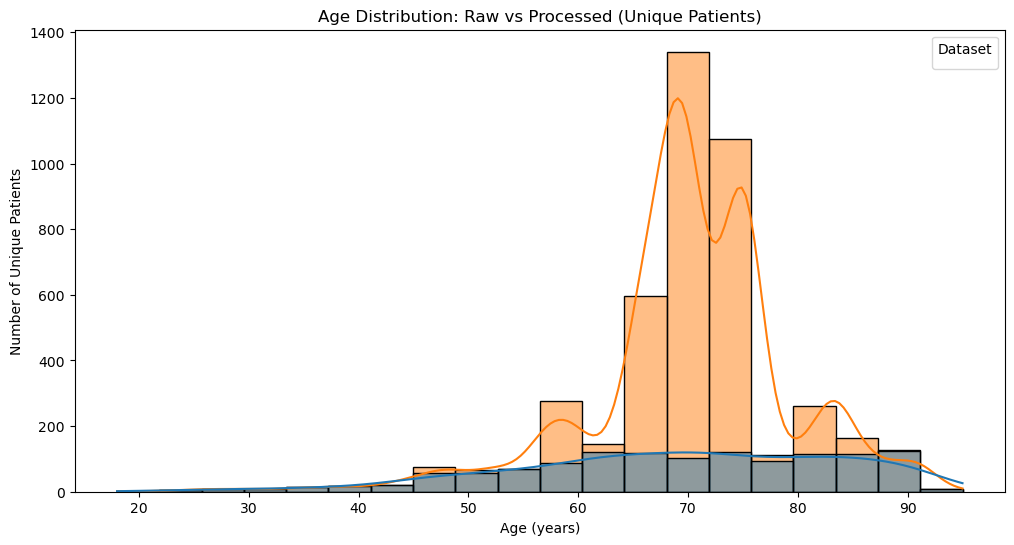

/var/folders/6c/ryq330rs7bl7nmdhthbq78380000gn/T/ipykernel_36377/1628425679.py:31: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=combined, x="dataset", y="age", palette="Set2")


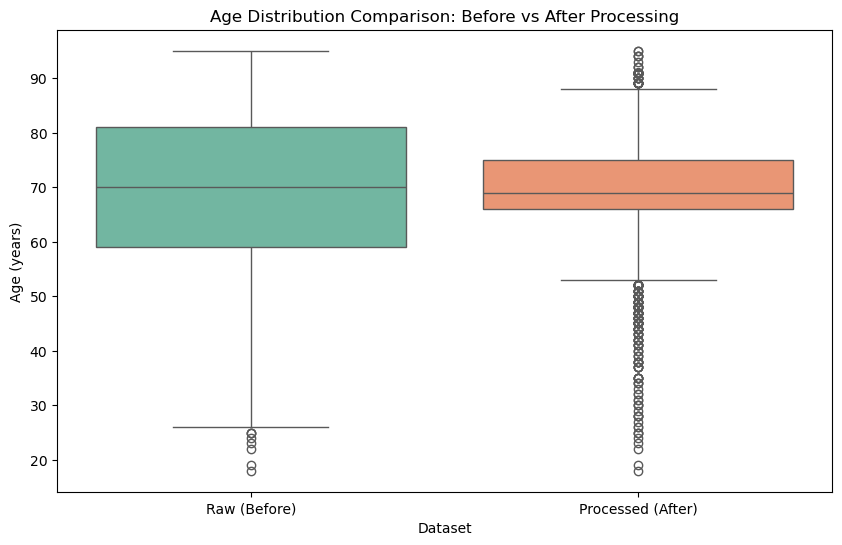

/var/folders/6c/ryq330rs7bl7nmdhthbq78380000gn/T/ipykernel_36377/1628425679.py:39: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=combined, x="dataset", y="age", palette="muted")


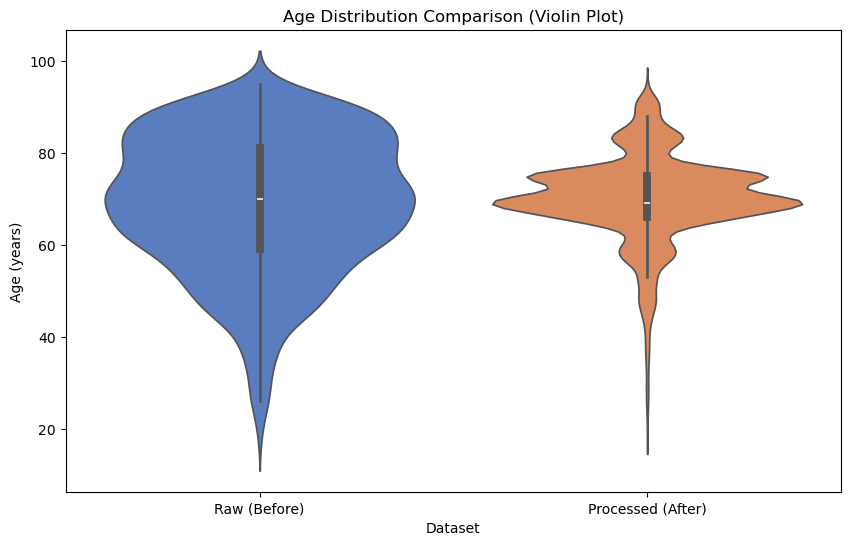

=== RAW DATASET ===
Unique patients: 1264
Mean age: 68.84
Median age: 70.00
Missing values: 3128

=== PROCESSED DATASET ===
Unique patients: 4392
Mean age: 70.09
Median age: 69.00
Missing values: 0


In [14]:
# Create visual comparisons and statistics of age distributions before and after processing.

import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd

heart_diagnoses_raw = pd.read_csv("../../data/raw/heart_diagnoses_1.csv")

heart_diagnoses_processed = pd.read_csv("../../data/processed/hd.csv")

unique_patients_raw = heart_diagnoses_raw.groupby("subject_id")["age"].first().reset_index()
unique_patients_raw = unique_patients_raw[unique_patients_raw['age'].notna()]  # Remove NaN

unique_patients_processed = heart_diagnoses_processed.groupby("subject_id")["age"].first().reset_index()

unique_patients_raw['dataset'] = 'Raw (Before)'
unique_patients_processed['dataset'] = 'Processed (After)'
combined = pd.concat([unique_patients_raw, unique_patients_processed])

# Option 1: Overlaid histograms
plt.figure(figsize=(12, 6))
sns.histplot(data=combined, x="age", hue="dataset", bins=20, kde=True, alpha=0.5)
plt.title("Age Distribution: Raw vs Processed (Unique Patients)")
plt.xlabel("Age (years)")
plt.ylabel("Number of Unique Patients")
plt.legend(title="Dataset")
plt.show()

# Option 2: Comparative boxplot
plt.figure(figsize=(10, 6))
sns.boxplot(data=combined, x="dataset", y="age", palette="Set2")
plt.title("Age Distribution Comparison: Before vs After Processing")
plt.ylabel("Age (years)")
plt.xlabel("Dataset")
plt.show()

# Option 3: Violin plot
plt.figure(figsize=(10, 6))
sns.violinplot(data=combined, x="dataset", y="age", palette="muted")
plt.title("Age Distribution Comparison (Violin Plot)")
plt.ylabel("Age (years)")
plt.xlabel("Dataset")
plt.show()

# Comparative statistics
print("=== RAW DATASET ===")
print(f"Unique patients: {unique_patients_raw.shape[0]}")
print(f"Mean age: {unique_patients_raw['age'].mean():.2f}")
print(f"Median age: {unique_patients_raw['age'].median():.2f}")
print(f"Missing values: {heart_diagnoses_raw.groupby('subject_id')['age'].first().isna().sum()}")

print("\n=== PROCESSED DATASET ===")
print(f"Unique patients: {unique_patients_processed.shape[0]}")
print(f"Mean age: {unique_patients_processed['age'].mean():.2f}")
print(f"Median age: {unique_patients_processed['age'].median():.2f}")
print(f"Missing values: {unique_patients_processed['age'].isna().sum()}")

In [15]:
# Check how many patients lack any gender information.

patients_with_gender_info = (
    heart_diagnoses_df.groupby("subject_id")["gender"]
    .apply(lambda x: x.notna().any())   # True if at least one record has gender
)

patients_without_gender_info = patients_with_gender_info[~patients_with_gender_info]

num_patients_without_gender_info = patients_without_gender_info.shape[0]

print(f"Number of patients without any gender information: {num_patients_without_gender_info}")



Number of patients without any gender information: 29


In [16]:
# Imputes missing gender for patients with a single admission by sampling M/F at random according to the observed gender proportions within each ICD code; if an ICD has no observed genders, it falls back to the global dataset proportions (seeded for reproducibility).

np.random.seed(42)

def fill_with_proportions(group, global_props=None):
    missing_mask = group['gender'].isna()
    if missing_mask.sum() == 0:
        return group
    
    value_counts = group['gender'].value_counts()
    
    if value_counts.empty:
        # If there are no observed values for that ICD
        if global_props is not None:
            # Use global proportions
            choices = np.random.choice(global_props.index, size=missing_mask.sum(), p=global_props.values)
            group.loc[missing_mask, 'gender'] = choices
        else:
            # Otherwise assign a default 'M'
            group.loc[missing_mask, 'gender'] = 'M'
    else:
        # Use local ICD proportions
        proportions = value_counts / value_counts.sum()
        choices = np.random.choice(value_counts.index, size=missing_mask.sum(), p=proportions.values)
        group.loc[missing_mask, 'gender'] = choices
    
    return group

# Compute global F/M proportions
global_props = heart_diagnoses_df['gender'].value_counts(normalize=True)

df_single_admission = heart_diagnoses_df[heart_diagnoses_df['subject_id'].isin(single_admission_patients)]
df_single_admission = df_single_admission.groupby('icd_code', group_keys=False).apply(fill_with_proportions, global_props=global_props)

heart_diagnoses_df.update(df_single_admission)

print(f"Missing values in gender (single admission): {df_single_admission['gender'].isna().sum()}")
print(df_single_admission['gender'].value_counts())

Missing values in gender (single admission): 0
gender
M    2558
F    1443
Name: count, dtype: int64


/var/folders/6c/ryq330rs7bl7nmdhthbq78380000gn/T/ipykernel_36377/2271112912.py:33: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  df_single_admission = df_single_admission.groupby('icd_code', group_keys=False).apply(fill_with_proportions, global_props=global_props)


In [17]:
# Fill missing gender using other admissions of the same subject

multi_admission_subjects = (
    heart_diagnoses_df.groupby('subject_id')['hadm_id'].nunique().gt(1)
)

gender_lookup = (
    heart_diagnoses_df[heart_diagnoses_df['gender'].notna()]
    .sort_values('hadm_id')
    .drop_duplicates('subject_id', keep='first')
    .set_index('subject_id')['gender']
)

mask_missing_gender = heart_diagnoses_df['gender'].isna()
mask_multi_with_gender = (
    multi_admission_subjects.reindex(heart_diagnoses_df['subject_id']).fillna(False).values &
    heart_diagnoses_df['subject_id'].isin(gender_lookup.index)
)

heart_diagnoses_df.loc[mask_missing_gender & mask_multi_with_gender, 'gender'] = (
    heart_diagnoses_df.loc[mask_missing_gender & mask_multi_with_gender, 'subject_id']
    .map(gender_lookup)
)

print(f"Missing values in gender (multi admission): {heart_diagnoses_df['gender'].isna().sum()}")

Missing values in gender (multi admission): 0


In [18]:
# Recompute count of patients without gender after imputation steps.

patients_with_gender_info = (
    heart_diagnoses_df.groupby("subject_id")["gender"]
    .apply(lambda x: x.notna().any())   # True if at least one record has gender
)

patients_without_gender_info = patients_with_gender_info[~patients_with_gender_info]

num_patients_without_gender_info = patients_without_gender_info.shape[0]

print(f"Number of patients without any gender info: {num_patients_without_gender_info}")


Number of patients without any gender info: 0


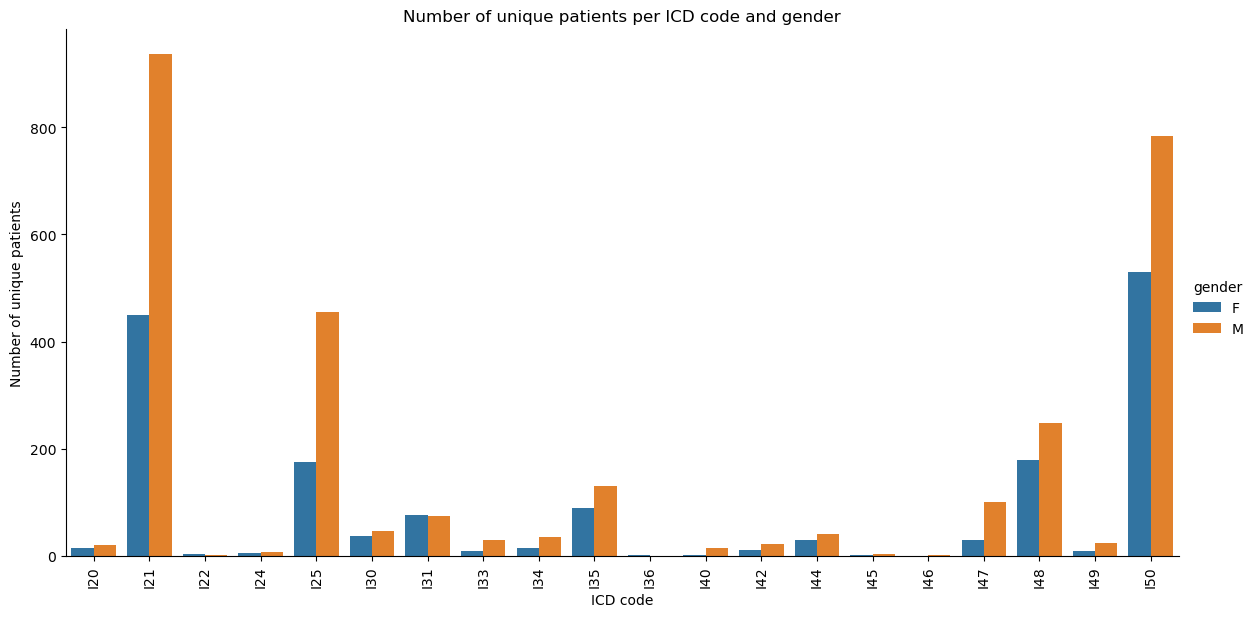

In [19]:
# Plot number of unique patients per ICD code split by gender.

unique_counts = (
    heart_diagnoses_df
    .groupby(["icd_code", "gender"])["subject_id"]
    .nunique()
    .reset_index()
)

sns.catplot(
    data=unique_counts,
    x="icd_code",
    y="subject_id",   # now it's the number of unique patients
    hue="gender",
    kind="bar",
    height=6,
    aspect=2
)

plt.title("Number of unique patients per ICD code and gender")
plt.ylabel("Number of unique patients")
plt.xlabel("ICD code")
plt.xticks(rotation=90)
plt.show()

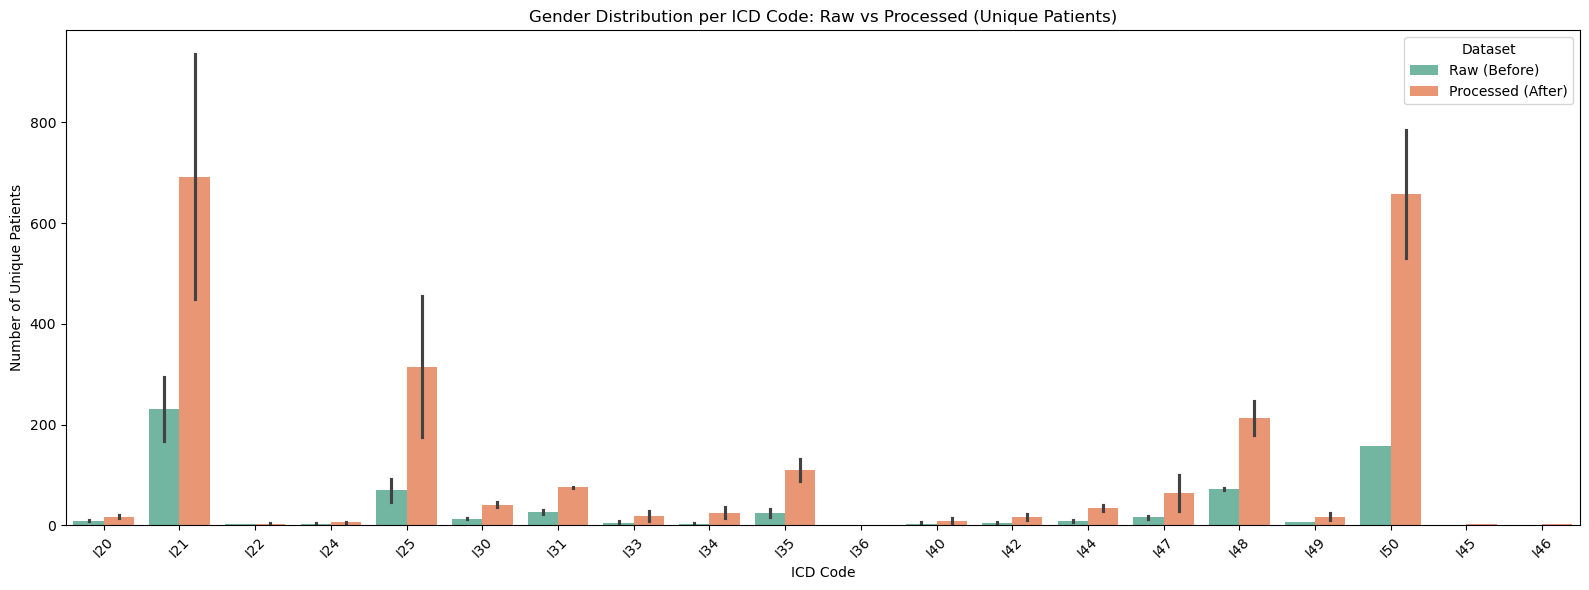

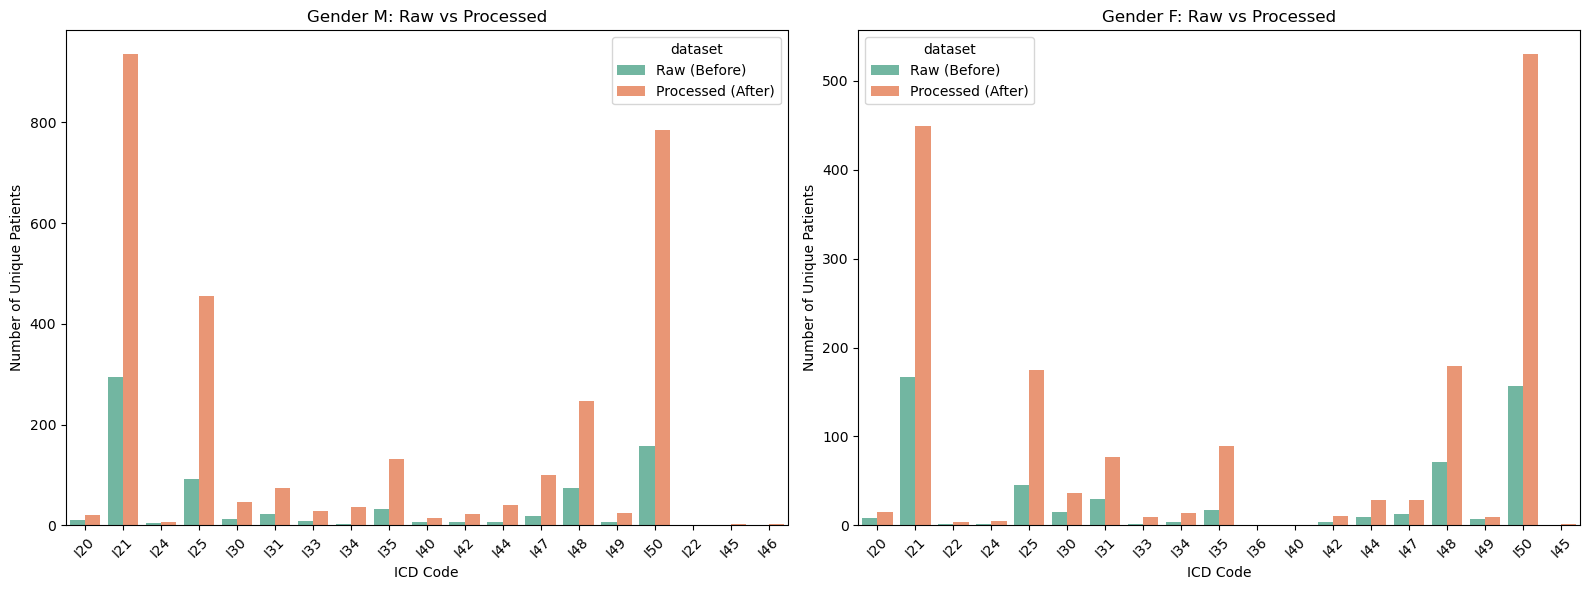

=== RAW DATASET ===
Gender distribution per ICD code:
gender        F      M
icd_code              
I20         8.0   10.0
I21       167.0  295.0
I22         2.0    0.0
I24         2.0    5.0
I25        46.0   93.0
I30        15.0   12.0
I31        30.0   22.0
I33         2.0    8.0
I34         4.0    2.0
I35        17.0   32.0
I36         1.0    0.0
I40         1.0    6.0
I42         4.0    6.0
I44        10.0    7.0
I47        13.0   19.0
I48        71.0   74.0
I49         7.0    6.0
I50       157.0  158.0

=== PROCESSED DATASET ===
Gender distribution per ICD code:
gender        F      M
icd_code              
I20        15.0   20.0
I21       449.0  936.0
I22         4.0    1.0
I24         5.0    7.0
I25       175.0  456.0
I30        37.0   46.0
I31        77.0   75.0
I33         9.0   29.0
I34        14.0   36.0
I35        89.0  131.0
I36         1.0    0.0
I40         1.0   15.0
I42        11.0   22.0
I44        29.0   41.0
I45         2.0    3.0
I46         0.0    2.0
I47        

In [20]:
# Compare gender distribution per ICD between raw and processed datasets and plot results.

heart_diagnoses_raw = pd.read_csv("../../data/raw/heart_diagnoses_1.csv")
heart_diagnoses_processed = pd.read_csv("../../data/processed/hd.csv")

unique_gender_per_icd_raw = (
    heart_diagnoses_raw[heart_diagnoses_raw['gender'].notna()]
    .groupby(["icd_code", "gender"])["subject_id"]
    .nunique()
    .reset_index()
    .rename(columns={"subject_id": "num_patients"})
)
unique_gender_per_icd_raw['dataset'] = 'Raw (Before)'

unique_gender_per_icd_processed = (
    heart_diagnoses_processed
    .groupby(["icd_code", "gender"])["subject_id"]
    .nunique()
    .reset_index()
    .rename(columns={"subject_id": "num_patients"})
)
unique_gender_per_icd_processed['dataset'] = 'Processed (After)'

combined_gender_icd = pd.concat([unique_gender_per_icd_raw, unique_gender_per_icd_processed])

# Comparative bar chart
plt.figure(figsize=(16, 6))
sns.barplot(data=combined_gender_icd, x="icd_code", y="num_patients", hue="dataset", palette="Set2")
plt.title("Gender Distribution per ICD Code: Raw vs Processed (Unique Patients)")
plt.xlabel("ICD Code")
plt.ylabel("Number of Unique Patients")
plt.xticks(rotation=45)
plt.legend(title="Dataset")
plt.tight_layout()
plt.show()

# Separate plots by gender
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

for idx, gender in enumerate(['M', 'F']):
    data_gender = combined_gender_icd[combined_gender_icd['gender'] == gender]
    sns.barplot(data=data_gender, x="icd_code", y="num_patients", hue="dataset", palette="Set2", ax=axes[idx])
    axes[idx].set_title(f"Gender {gender}: Raw vs Processed")
    axes[idx].set_xlabel("ICD Code")
    axes[idx].set_ylabel("Number of Unique Patients")
    axes[idx].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

# Comparative tables
print("=== RAW DATASET ===")
print(f"Gender distribution per ICD code:\n{unique_gender_per_icd_raw.pivot_table(index='icd_code', columns='gender', values='num_patients', fill_value=0)}")

print("\n=== PROCESSED DATASET ===")
print(f"Gender distribution per ICD code:\n{unique_gender_per_icd_processed.pivot_table(index='icd_code', columns='gender', values='num_patients', fill_value=0)}")

In [21]:
#Drop redundant identifier columns collected elsewhere in the dataset.

heart_diagnoses_df=heart_diagnoses_df.drop(columns=["note_id","subject_id_dx"])


In [22]:
# Print final dataset shape, info, missing-value summary and basic statistics.

print("Shape of heart diagnoses dataset:", heart_diagnoses_df.shape)
print("Info of heart diagnoses dataset:")
heart_diagnoses_df.info()
heart_diagnoses_df_none=du.get_cols_with_none(heart_diagnoses_df)
print("Missing values in each column of heart diagnoses dataset:\n",heart_diagnoses_df_none)
print("Basic statistics of heart diagnoses dataset:")
du.get_basic_stats(heart_diagnoses_df)


Shape of heart diagnoses dataset: (4864, 6)
Info of heart diagnoses dataset:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4864 entries, 0 to 4863
Data columns (total 6 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   subject_id  4864 non-null   int64 
 1   hadm_id     4864 non-null   int64 
 2   icd_code    4864 non-null   object
 3   long_title  4864 non-null   object
 4   gender      4864 non-null   object
 5   age         4864 non-null   Int64 
dtypes: Int64(1), int64(2), object(3)
memory usage: 232.9+ KB
Missing values in each column of heart diagnoses dataset:
 subject_id    False
hadm_id       False
icd_code      False
long_title    False
gender        False
age           False
dtype: bool
Basic statistics of heart diagnoses dataset:


,age
count,4864.0
mean,70.256579
std,9.307326
min,18.0
25%,66.0
50%,70.0
75%,75.0
max,95.0


In [23]:
# Compute descriptive statistics of age per unique patient.

unique_patients = heart_diagnoses_df.groupby("subject_id")["age"].first().reset_index()
age_stats = unique_patients['age'].describe()
print("Statistical analysis of age per unique patient:\n",age_stats)


Statistical analysis of age per unique patient:
 count       4392.0
mean     70.093807
std       9.436061
min           18.0
25%           66.0
50%           69.0
75%           75.0
max           95.0
Name: age, dtype: Float64


In [24]:
# Calculate mean and median age per ICD code for analysis.

icd_stats = heart_diagnoses_df.groupby('icd_code')['age'].agg(['mean', 'median']).reset_index()
icd_stats.columns = ['icd_code', 'mean_age', 'median_age']
print("Mean and median age for each ICD code:\n", icd_stats)

Mean and median age for each ICD code:
    icd_code   mean_age  median_age
0       I20  57.027778        60.0
1       I21  68.956764        69.0
2       I22       88.4        90.0
3       I24  69.333333        69.0
4       I25  66.172093        66.0
5       I30   59.60241        59.0
6       I31   57.79085        57.0
7       I33  57.236842        59.0
8       I34      71.16        71.0
9       I35  81.623377        83.0
10      I36       60.0        60.0
11      I40    49.5625        52.0
12      I42  51.151515        48.0
13      I44       82.4        84.0
14      I45       75.0        75.0
15      I46       75.0        75.0
16      I47  68.938462        69.0
17      I48  71.070776        71.0
18      I49  63.857143        64.0
19      I50   74.15273        75.0


<Axes: xlabel='icd_code', ylabel='Count'>

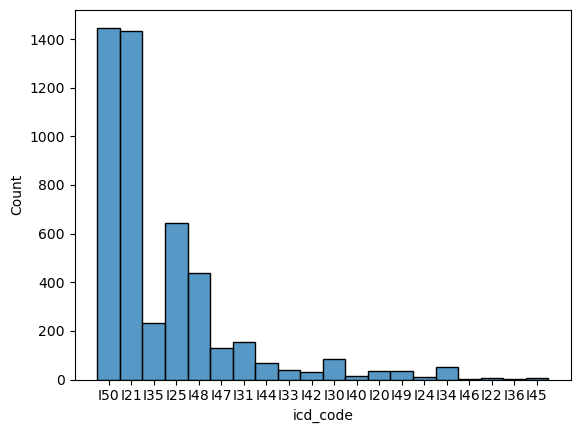

In [25]:
# Visualize ICD code distribution with a histogram.
sns.histplot(heart_diagnoses_df, x="icd_code")


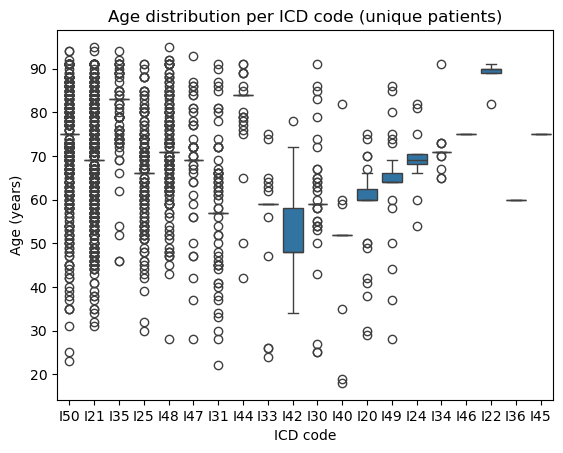

In [26]:
# Show age distribution per ICD code using boxplots on unique patient-ICD pairs.

unique_patients_icd = heart_diagnoses_df[["subject_id", "icd_code", "age"]].drop_duplicates(subset=["subject_id", "icd_code"])

sns.boxplot(data=unique_patients_icd, x="icd_code", y="age")
plt.title("Age distribution per ICD code (unique patients)")
plt.xlabel("ICD code")
plt.ylabel("Age (years)")
plt.show()

In [27]:
# Print final shape of the processed dataset.

print("Final shape of heart diagnoses dataset:", heart_diagnoses_df.shape)


Final shape of heart diagnoses dataset: (4864, 6)


In [28]:
# Save the processed dataframe to CSV in the processed data folder.

heart_diagnoses_df.to_csv("../../data/processed/hd.csv", index=False)